# 12 — Synthetic statistical validation and real-world comparison

This notebook evaluates the synthetic Indian-university planner data as a generated development resource. It checks relational integrity, tests feature associations with the simulated risk label, audits student-disjoint train/test composition, and compares the common engagement contract with OULAD and the authorised KU Leuven release.

The synthetic dataset is not treated as real-student evidence. Statistical significance can reveal relationships created by the simulator, but it cannot establish that sleep, screen time, break time, CGPA, wellbeing, or Indian-university attributes have the same distributions or effects in a real population.

## Formal statistical protocol

The report uses alpha = 0.05 with Holm-Bonferroni correction within each test family. Numeric comparisons use Kolmogorov-Smirnov and Mann-Whitney tests with medians, quartiles, and Cliff's delta. Risk-rate comparisons use two-row chi-square tests. The student-disjoint split is an audit of cohort composition and is separate from the baseline model's locked-test evaluation.

The external comparison uses only a narrow shared engagement contract: activity count, active days, content count, session count, mean daily activity, and activity presence. The mapping is a measurement proxy across schemas; it is not a claim that a synthetic study session is semantically identical to an LMS action.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from pipeline.statistical_validation import run_synthetic_statistical_validation

CUTOFFS = (30, 60, 90)
REPORT_PATH = PROJECT_ROOT / 'models' / 'validation' / 'synthetic_statistical_validation.json'
report = run_synthetic_statistical_validation(
    data_dir=PROJECT_ROOT / 'data' / 'raw' / 'synthetic',
    oulad_dir=PROJECT_ROOT / 'data' / 'processed' / 'oulad',
    kuleuven_path=PROJECT_ROOT / 'data' / 'raw' / 'external' / 'kuleuven' / 'dataset.zip',
    output=REPORT_PATH,
    cutoffs=CUTOFFS,
)
print(f"Saved measured report to {REPORT_PATH}")
print(f"Integrity status: {report['integrity_validation']['status']}")

Saved measured report to D:\AI PROJECTS\C++\Smart-Study-Planner\models\validation\synthetic_statistical_validation.json
Integrity status: passed


## 1. Relational integrity and generated-record status

Relational checks are a prerequisite for meaningful statistical testing. They verify manifest counts, primary-key uniqueness, and foreign-key relationships. Passing these checks means the generated release is internally coherent; it does not mean that its distributions are realistic.

In [2]:
integrity = report['integrity_validation']
checks = pd.DataFrame(integrity['checks'])
print(f"Status: {integrity['status']}")
display(checks.groupby('check', as_index=False)['passed'].agg(['count', 'sum']).reset_index())
display(pd.DataFrame([{'table': key, 'rows': value} for key, value in integrity['table_row_counts'].items()]).sort_values('rows', ascending=False).head(15))
print('Warnings:')
for warning in integrity['warnings']:
    print('-', warning)

Status: passed


,index,check,count,sum
0,0,foreign_key_integrity,10,10
1,1,manifest_row_count,36,36
2,2,primary_key_integrity,6,6


,table,rows
15,daily_wellbeing,336000
27,sleep_records,336000
6,availability,336000
5,attendance_records,192000
31,student_topic_state,144000
33,study_sessions,96000
23,planner_recommendations,96000
7,break_records,59660
25,recommendation_feedback,56883
26,resource_interactions,43529


Warnings:
- Rows are simulated and are not observations about real students.
- Behaviour distributions are assumptions for development and testing.
- Synthetic performance must not be reported as real-world model evidence.
- External validity against a real university population was not assessed.


## 2. Associations with the simulated risk label

The association tests compare each declared planner feature between `risk_label = 0` and `risk_label = 1`. The comparison is useful for detecting whether the generated data contains the intended signal. It is not causal evidence: a simulator can create an association through a shared latent variable, deterministic rule, or correlated generation process.

,cutoff_days,feature,reference_median,comparison_median,mann_whitney_p_value_holm,cliffs_delta,mann_whitney_significant_005
0,30,prior_cumulative_gpa,6.620000,5.130000,4.362889e-32,-0.695260,True
1,30,attendance_pct_at_cutoff,80.000000,60.000000,6.134364e-40,-0.602495,True
2,30,assessment_mean_score,89.790000,72.460000,1.689429e-43,-0.656039,True
3,30,active_study_minutes,91.000000,69.000000,3.359829e-14,-0.357404,True
4,30,session_completion_rate,1.000000,0.500000,2.989142e-30,-0.397545,True
5,30,mean_sleep_hours,6.535464,5.740951,2.717373e-38,-0.616271,True
6,30,mean_total_screen_minutes,225.612903,192.236948,1.710925e-36,-0.600574,True
7,30,mean_stress_score,4.188750,4.445915,5.540778e-31,0.549944,True
8,30,mean_available_hours,2.402903,1.555862,1.770902e-38,-0.618354,True
9,60,prior_cumulative_gpa,6.620000,5.130000,2.181445e-32,-0.695260,True


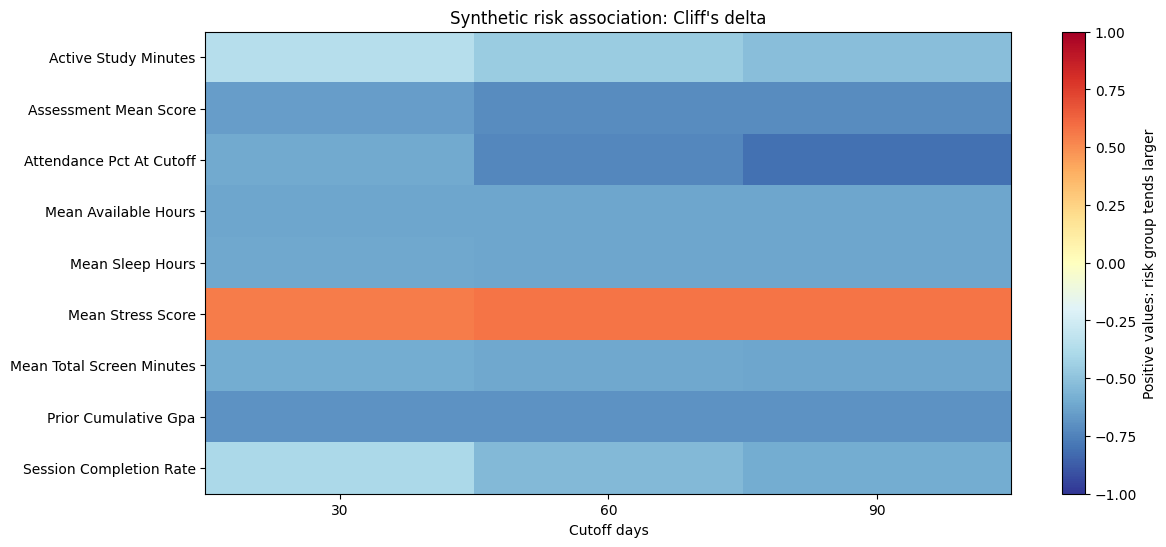

In [3]:
association_rows = []
for cutoff, rows in report['risk_association_tests']['numeric_feature_tests_by_cutoff'].items():
    for row in rows:
        association_rows.append({'cutoff_days': int(cutoff), **row})
association = pd.DataFrame(association_rows)
display(association[['cutoff_days', 'feature', 'reference_median', 'comparison_median', 'mann_whitney_p_value_holm', 'cliffs_delta', 'mann_whitney_significant_005']])

fig, ax = plt.subplots(figsize=(13, 6))
pivot = association.pivot(index='feature', columns='cutoff_days', values='cliffs_delta')
image = ax.imshow(pivot.fillna(0).to_numpy(), cmap='RdYlBu_r', aspect='auto', vmin=-1, vmax=1)
ax.set_xticks(range(len(pivot.columns)), [str(value) for value in pivot.columns])
ax.set_yticks(range(len(pivot.index)), [str(value).replace('_', ' ').title() for value in pivot.index])
ax.set_xlabel('Cutoff days')
ax.set_title("Synthetic risk association: Cliff's delta")
fig.colorbar(image, ax=ax, label='Positive values: risk group tends larger')
plt.show()

## 3. Student-disjoint train/test composition

The baseline model assigns entire students—not individual enrollment rows—to train and test. The following tests compare numeric planner-feature distributions across those partitions. A significant difference indicates potential composition shift in this split; a non-significant result is not proof that the synthetic population is representative.

,cutoff_days,feature,reference_median,comparison_median,ks_p_value_holm,cliffs_delta,ks_significant_005
0,30,prior_cumulative_gpa,6.585000,6.615000,0.022879,-0.001167,True
1,30,attendance_pct_at_cutoff,80.000000,80.000000,1.000000,-0.000104,False
2,30,assessment_mean_score,89.450000,89.230000,0.792698,0.004700,False
3,30,active_study_minutes,91.000000,90.000000,0.792698,-0.018313,False
4,30,session_completion_rate,1.000000,1.000000,1.000000,-0.012396,False
5,30,mean_sleep_hours,6.503697,6.540534,0.000334,0.019834,True
6,30,mean_total_screen_minutes,225.032258,224.115022,0.002753,-0.023169,True
7,30,mean_stress_score,4.190734,4.195918,0.311737,0.004215,False
8,30,mean_available_hours,2.379109,2.372341,0.000017,-0.014414,True
9,60,prior_cumulative_gpa,6.585000,6.615000,0.022879,-0.001167,True


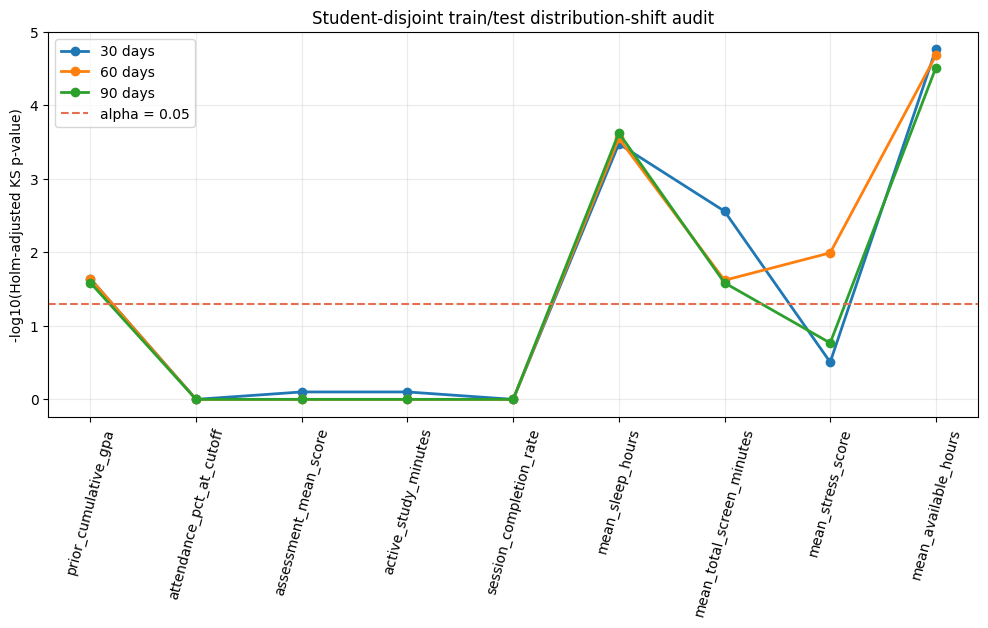

In [4]:
shift_rows = []
for cutoff, rows in report['student_disjoint_split_validation']['numeric_distribution_tests_by_cutoff'].items():
    for row in rows:
        shift_rows.append({'cutoff_days': int(cutoff), **row})
shift = pd.DataFrame(shift_rows)
display(shift[['cutoff_days', 'feature', 'reference_median', 'comparison_median', 'ks_p_value_holm', 'cliffs_delta', 'ks_significant_005']])

fig, ax = plt.subplots(figsize=(12, 5))
for cutoff, group in shift.groupby('cutoff_days'):
    ax.plot(group['feature'], -np.log10(group['ks_p_value_holm'].clip(lower=1e-300)), marker='o', linewidth=2, label=f'{cutoff} days')
ax.axhline(-np.log10(0.05), color='#e76f51', linestyle='--', label='alpha = 0.05')
ax.set_ylabel('-log10(Holm-adjusted KS p-value)')
ax.set_title('Student-disjoint train/test distribution-shift audit')
ax.tick_params(axis='x', rotation=75)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

## 4. Comparison with real educational datasets

The synthetic data is compared with the KU Leuven 2021 locked cohort and the latest OULAD presentation. The common fields are activity count, active days, content count, session count, mean daily activity, and activity presence. The tests are a stress test of measurement compatibility. They cannot validate constructs absent from the real releases, including sleep, break time, screen time, wellbeing, CGPA, and Indian-university context.

In [5]:
external_rows = []
for reference_group, by_cutoff in [('KU Leuven', report['real_world_comparison']['synthetic_vs_kuleuven_by_cutoff']), ('OULAD', report['real_world_comparison']['synthetic_vs_oulad_by_cutoff'])]:
    for cutoff, comparison in by_cutoff.items():
        for row in comparison['numeric_distribution_tests']:
            external_rows.append({'cutoff_days': int(cutoff), 'reference_dataset': reference_group, **row})
external = pd.DataFrame(external_rows)
display(external[['cutoff_days', 'reference_dataset', 'feature', 'reference_median', 'comparison_median', 'ks_p_value_holm', 'cliffs_delta', 'ks_significant_005']])

,cutoff_days,reference_dataset,feature,reference_median,comparison_median,ks_p_value_holm,cliffs_delta,ks_significant_005
0,30,KU Leuven,activity_count,2.0,384.000000,0.0,0.979092,True
1,30,KU Leuven,active_day_count,2.0,16.000000,0.0,0.955683,True
2,30,KU Leuven,content_count,2.0,47.000000,0.0,0.972838,True
3,30,KU Leuven,mean_daily_activity,1.0,25.133333,0.0,0.979986,True
4,60,KU Leuven,activity_count,4.5,800.000000,0.0,0.988563,True
5,60,KU Leuven,active_day_count,4.5,29.000000,0.0,0.940315,True
6,60,KU Leuven,content_count,2.0,73.000000,0.0,0.985704,True
7,60,KU Leuven,mean_daily_activity,1.0,30.484848,0.0,0.991422,True
8,90,KU Leuven,activity_count,6.5,1253.000000,0.0,0.989993,True
9,90,KU Leuven,active_day_count,6.5,40.000000,0.0,0.932809,True


,dataset,cutoff_days,selected_model,pr_auc,roc_auc,balanced_accuracy,f1,brier_score
0,OULAD,30,hist_gradient_boosting,0.825576,0.802754,0.730635,0.735760,0.186244
1,OULAD,60,hist_gradient_boosting,0.870224,0.846169,0.761332,0.775719,0.168348
2,OULAD,90,hist_gradient_boosting,0.888122,0.864619,0.766858,0.784848,0.165973
3,Synthetic,30,extra_trees,0.077657,0.900129,0.500000,0.000000,0.012374
4,Synthetic,60,logistic_regression,0.115243,0.918574,0.500000,0.000000,0.012297
5,Synthetic,90,extra_trees,0.070122,0.907784,0.500000,0.000000,0.012647
6,KU Leuven,30,logistic_regression,0.540837,0.675425,0.590733,0.375522,0.220881
7,KU Leuven,60,logistic_regression,0.566409,0.698626,0.624696,0.467662,0.211388
8,KU Leuven,90,logistic_regression,0.605750,0.720735,0.643293,0.508876,0.200656


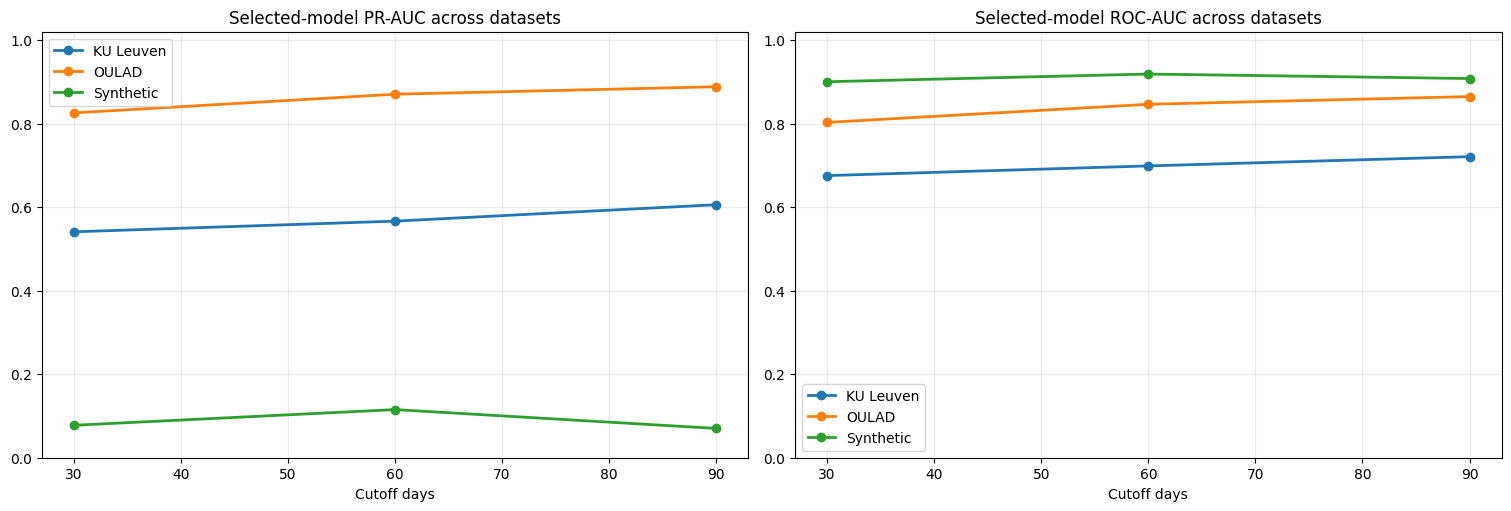

In [6]:
metric_table = pd.DataFrame(report['real_world_comparison']['selected_model_metric_comparison'])
display(metric_table[['dataset', 'cutoff_days', 'selected_model', 'pr_auc', 'roc_auc', 'balanced_accuracy', 'f1', 'brier_score']])

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for dataset, group in metric_table.groupby('dataset'):
    group = group.sort_values('cutoff_days')
    axes[0].plot(group['cutoff_days'], group['pr_auc'], marker='o', linewidth=2, label=dataset)
    axes[1].plot(group['cutoff_days'], group['roc_auc'], marker='o', linewidth=2, label=dataset)
axes[0].set_title('Selected-model PR-AUC across datasets')
axes[1].set_title('Selected-model ROC-AUC across datasets')
for axis in axes:
    axis.set_xlabel('Cutoff days')
    axis.set_ylim(0, 1.02)
    axis.grid(alpha=0.25)
    axis.legend()
plt.show()

## Formal conclusion and limitations

The synthetic release can be judged internally coherent when the relational checks pass and its declared statistical relationships are measurable. It cannot be judged realistic solely because a model obtains a strong ROC-AUC, because the generator may encode the same relationships used by the model. The real-world comparisons provide evidence about the limited common engagement contract only.

A large difference in risk prevalence or engagement distributions is expected across institutions and may explain why a model trained on one source does not transfer to another. It does not prove that the synthetic planner fields are invalid, but it means those fields remain development assumptions until tested with an authorised dataset containing the same constructs. Prospective validation, subgroup review, calibration, and intervention evaluation remain outstanding.